In [33]:
#Data Analysis and calculation
import pandas as pd
import numpy as np

import os

import warnings
warnings.filterwarnings('ignore')

#Data Visualization
import seaborn as sns
import matplotlib.pyplot as plt
from PIL import Image
%matplotlib inline
import plotly.offline as py
py.init_notebook_mode(connected=True)
import plotly.graph_objs as go
import plotly.tools as tls
import plotly.figure_factory as ff

#Model Building and Data prediction
import statsmodels.api as sm
from statsmodels.stats import diagnostic as diag
from sklearn.model_selection import train_test_split

In [52]:
new = pd.read_csv('Bank_Loan.csv')
new.head()

,Loan_ID,Age,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,LoanAmount,Previous_Loan_Taken,Cibil_Score,Property_Area,Customer_Bandwith,Tenure,Loan_Status
0,LP001002,43,Male,No,3,Graduate,No,54005,334113,Yes,668,Urban,Good,43,No
1,LP001003,57,Male,Yes,2,Graduate,No,28817,736026,Yes,684,Rural,Good,13,Yes
2,LP001005,25,Male,Yes,3,Graduate,Yes,99939,712432,Yes,788,Urban,Good,10,No
3,LP001006,44,Male,Yes,1,Not Graduate,No,38470,267161,Yes,888,Urban,Good,9,No
4,LP001008,58,Male,No,1,Graduate,No,28991,402474,Yes,703,Urban,Good,11,No


In [35]:
import pandas as pd
Bank = pd.read_csv ('/content/Bank_Loan.csv')
Bank.head()

,Loan_ID,Age,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,LoanAmount,Previous_Loan_Taken,Cibil_Score,Property_Area,Customer_Bandwith,Tenure,Loan_Status
0,LP001002,43,Male,No,3,Graduate,No,54005,334113,Yes,668,Urban,Good,43,No
1,LP001003,57,Male,Yes,2,Graduate,No,28817,736026,Yes,684,Rural,Good,13,Yes
2,LP001005,25,Male,Yes,3,Graduate,Yes,99939,712432,Yes,788,Urban,Good,10,No
3,LP001006,44,Male,Yes,1,Not Graduate,No,38470,267161,Yes,888,Urban,Good,9,No
4,LP001008,58,Male,No,1,Graduate,No,28991,402474,Yes,703,Urban,Good,11,No


In [36]:
Bank.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 981 entries, 0 to 980
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Loan_ID              981 non-null    object
 1   Age                  981 non-null    int64 
 2   Gender               957 non-null    object
 3   Married              978 non-null    object
 4   Dependents           981 non-null    int64 
 5   Education            981 non-null    object
 6   Self_Employed        926 non-null    object
 7   ApplicantIncome      981 non-null    int64 
 8   LoanAmount           981 non-null    int64 
 9   Previous_Loan_Taken  981 non-null    object
 10  Cibil_Score          981 non-null    int64 
 11  Property_Area        981 non-null    object
 12  Customer_Bandwith    981 non-null    object
 13  Tenure               981 non-null    int64 
 14  Loan_Status          981 non-null    object
dtypes: int64(6), object(9)
memory usage: 115.1+ KB


In [37]:
Bank.isnull().sum()

,0
Loan_ID,0
Age,0
Gender,24
Married,3
Dependents,0
Education,0
Self_Employed,55
ApplicantIncome,0
LoanAmount,0
Previous_Loan_Taken,0


In [38]:
Bank.Gender.value_counts(dropna=False)

,count
Gender,
Male,775
Female,182
NaN,24


In [39]:
for i in['Married','Gender','Self_Employed']:
  Bank[i].fillna(Bank[i].mode()[0],inplace=True)


In [40]:
Bank.Gender.value_counts(dropna=False)

,count
Gender,
Male,799
Female,182


In [41]:
Bank.head()

,Loan_ID,Age,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,LoanAmount,Previous_Loan_Taken,Cibil_Score,Property_Area,Customer_Bandwith,Tenure,Loan_Status
0,LP001002,43,Male,No,3,Graduate,No,54005,334113,Yes,668,Urban,Good,43,No
1,LP001003,57,Male,Yes,2,Graduate,No,28817,736026,Yes,684,Rural,Good,13,Yes
2,LP001005,25,Male,Yes,3,Graduate,Yes,99939,712432,Yes,788,Urban,Good,10,No
3,LP001006,44,Male,Yes,1,Not Graduate,No,38470,267161,Yes,888,Urban,Good,9,No
4,LP001008,58,Male,No,1,Graduate,No,28991,402474,Yes,703,Urban,Good,11,No


In [42]:
#Tenure to categorical column
def tenuer_lab(Bank):
  if Bank["Tenuer"] <= 6 :
    return "Tenuer_0_6"
  elif Bank["Tenuer"] > 6 & (Bank["Tenuer"] <= 12) :
    return "Tenuer_7_12"
  elif Bank["Tenuer"] > 12 & (Bank["Tenuer"] <= 24) :
    return "Tenuer_12_24"
  elif Bank["Tenuer"] > 24 & (Bank["Tenuer"] <= 36) :
    return "Tenuer_25_36"
  elif Bank["Tenuer"] > 36:
    return "Tenuer_gt_36"
    # bank = x
    Bank["Tenure_group"] = Bank.apply(lambda x :tensure_lab(x),axis = 1)

In [43]:
Bank.head()

,Loan_ID,Age,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,LoanAmount,Previous_Loan_Taken,Cibil_Score,Property_Area,Customer_Bandwith,Tenure,Loan_Status
0,LP001002,43,Male,No,3,Graduate,No,54005,334113,Yes,668,Urban,Good,43,No
1,LP001003,57,Male,Yes,2,Graduate,No,28817,736026,Yes,684,Rural,Good,13,Yes
2,LP001005,25,Male,Yes,3,Graduate,Yes,99939,712432,Yes,788,Urban,Good,10,No
3,LP001006,44,Male,Yes,1,Not Graduate,No,38470,267161,Yes,888,Urban,Good,9,No
4,LP001008,58,Male,No,1,Graduate,No,28991,402474,Yes,703,Urban,Good,11,No


In [44]:
#Tenure to categorical column
def tenuer_lab(row):
  if row["Tenure"] <= 6 :
    return "Tenure_0_6"
  elif row["Tenure"] > 6 and row["Tenure"] <= 12 :
    return "Tenure_7_12"
  elif row["Tenure"] > 12 and row["Tenure"] <= 24 :
    return "Tenure_12_24"
  elif row["Tenure"] > 24 and row["Tenure"] <= 36 :
    return "Tenure_25_36"
  elif row["Tenure"] > 36:
    return "Tenure_gt_36"

In [45]:
Bank['Tenure_group'] = Bank.apply(lambda x :tenuer_lab(x),axis = 1)

In [46]:
Bank.Tenure_group.value_counts()

,count
Tenure_group,
Tenure_gt_36,267
Tenure_12_24,266
Tenure_25_36,259
Tenure_7_12,131
Tenure_0_6,58


<Axes: ylabel='ApplicantIncome'>

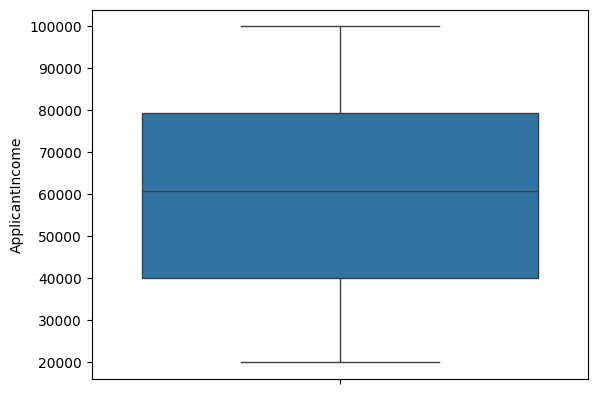

In [47]:
sns.boxplot(data=Bank.ApplicantIncome)

In [48]:
Bank.Tenure_group.value_counts()

,count
Tenure_group,
Tenure_gt_36,267
Tenure_12_24,266
Tenure_25_36,259
Tenure_7_12,131
Tenure_0_6,58


In [49]:
Bank.Loan_Status.value_counts(normalize=True)*100

,proportion
Loan_Status,
No,72.579001
Yes,27.420999


In [50]:
import plotly.express as px

fig = px.pie(Bank, names = "Loan_Status", color = "Loan_Status",
             color_discrete_map = {"Yes" : "red",
                                   "No" : "green"})

fig.show()

In [57]:
bank_Yes= Bank[Bank["Loan_Status"]=="Yes"]
bank_Yes

,Loan_ID,Age,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,LoanAmount,Previous_Loan_Taken,Cibil_Score,Property_Area,Customer_Bandwith,Tenure,Loan_Status,Tenure_group
1,LP001003,57,Male,Yes,2,Graduate,No,28817,736026,Yes,684,Rural,Good,13,Yes,Tenure_12_24
7,LP001014,54,Male,Yes,1,Graduate,No,53213,368715,No,447,Semiurban,Bad,17,Yes,Tenure_12_24
9,LP001020,33,Male,Yes,0,Graduate,No,57348,347577,Yes,378,Semiurban,Bad,18,Yes,Tenure_12_24
13,LP001029,32,Male,No,4,Graduate,No,43208,309303,Yes,585,Rural,Medium,39,Yes,Tenure_gt_36
17,LP001036,45,Female,No,2,Graduate,No,27568,830422,No,659,Urban,Good,35,Yes,Tenure_25_36
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
939,LP002802,24,Male,No,4,Graduate,No,29313,127392,No,618,Semiurban,Medium,36,Yes,Tenure_25_36
953,LP002858,57,Female,No,2,Graduate,No,91401,777888,No,726,Rural,Good,7,Yes,Tenure_7_12
956,LP002869,45,Male,Yes,4,Not Graduate,No,63617,421266,Yes,599,Rural,Medium,17,Yes,Tenure_12_24
960,LP002879,23,Male,Yes,4,Graduate,No,96201,996625,No,846,Rural,Good,22,Yes,Tenure_12_24


In [59]:
Bank = Bank.drop(["Loan_ID"],axis=1)
Bank.head()

KeyError: "['Loan_ID'] not found in axis"

In [62]:
Bank.select_dtypes(include=[np.number]).columns.tolist()

['Age', 'Dependents', 'ApplicantIncome', 'LoanAmount', 'Cibil_Score', 'Tenure']

In [63]:
Quantitative_Variable = Bank[Bank.select_dtypes(include=[np.number]).columns.tolist()]
Quantitative_Variable.head(3)

,Age,Dependents,ApplicantIncome,LoanAmount,Cibil_Score,Tenure
0,43,3,54005,334113,668,43
1,57,2,28817,736026,684,13
2,25,3,99939,712432,788,10


In [66]:
Quantitative_Variable= Bank[Bank.select_dtypes(include=['object']).columns.tolist()]
Quantitative_Variable.head(3)

,Gender,Married,Education,Self_Employed,Previous_Loan_Taken,Property_Area,Customer_Bandwith,Loan_Status,Tenure_group
0,Male,No,Graduate,No,Yes,Urban,Good,No,Tenure_gt_36
1,Male,Yes,Graduate,No,Yes,Rural,Good,Yes,Tenure_12_24
2,Male,Yes,Graduate,Yes,Yes,Urban,Good,No,Tenure_7_12


In [68]:
from sklearn.preprocessing import LabelEncoder
Quantitative_Variable=Quantitative_Variable.apply(LabelEncoder().fit_transform)
Quantitative_Variable.head()

,Gender,Married,Education,Self_Employed,Previous_Loan_Taken,Property_Area,Customer_Bandwith,Loan_Status,Tenure_group
0,1,0,0,0,1,2,1,0,4
1,1,1,0,0,1,0,1,1,1
2,1,1,0,1,1,2,1,0,3
3,1,1,1,0,1,2,1,0,3
4,1,0,0,0,1,2,1,0,3


In [73]:
numerical_variables_df = Bank.select_dtypes(include=[np.number])
encoded_categorical_df = Quantitative_Variable # This now holds the label-encoded object columns

Final_combined = pd.concat([numerical_variables_df, encoded_categorical_df], axis=1)
Final_combined.head()

,Age,Dependents,ApplicantIncome,LoanAmount,Cibil_Score,Tenure,Gender,Married,Education,Self_Employed,Previous_Loan_Taken,Property_Area,Customer_Bandwith,Loan_Status,Tenure_group
0,43,3,54005,334113,668,43,1,0,0,0,1,2,1,0,4
1,57,2,28817,736026,684,13,1,1,0,0,1,0,1,1,1
2,25,3,99939,712432,788,10,1,1,0,1,1,2,1,0,3
3,44,1,38470,267161,888,9,1,1,1,0,1,2,1,0,3
4,58,1,28991,402474,703,11,1,0,0,0,1,2,1,0,3


In [75]:
from sklearn.model_selection import train_test_split

X = Final_combined.drop(["Loan_Status"], axis = 1)
y = Final_combined["Loan_Status"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

In [76]:
train =pd.concat([X_train,y_train],axis=1)
train.head()

,Age,Dependents,ApplicantIncome,LoanAmount,Cibil_Score,Tenure,Gender,Married,Education,Self_Employed,Previous_Loan_Taken,Property_Area,Customer_Bandwith,Tenure_group,Loan_Status
975,45,0,76716,482646,739,6,1,1,0,0,1,1,1,0,0
625,32,5,81397,864553,761,12,1,1,0,0,1,1,1,3,0
931,42,1,58873,835054,793,20,1,1,1,0,0,2,1,1,1
33,59,1,68402,716371,767,12,1,1,0,0,1,1,1,3,0
31,47,4,51729,632909,776,8,1,0,0,0,1,2,1,3,1


In [79]:
from sklearn.feature_selection import SequentialFeatureSelector as sfs
from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression()
Model3 = sfs(logreg, n_features_to_select = 5, direction = "forward", scoring = "accuracy", cv=5)
Model3.fit(X_train, y_train)

SequentialFeatureSelector(estimator=LogisticRegression(),
                          n_features_to_select=5, scoring='accuracy')

In [81]:
Model3.feature_names_in_

array(['Age', 'Dependents', 'ApplicantIncome', 'LoanAmount',
       'Cibil_Score', 'Tenure', 'Gender', 'Married', 'Education',
       'Self_Employed', 'Previous_Loan_Taken', 'Property_Area',
       'Customer_Bandwith', 'Tenure_group'], dtype=object)

In [83]:
Model3.get_feature_names_out()


array(['ApplicantIncome', 'Cibil_Score', 'Gender', 'Self_Employed',
       'Previous_Loan_Taken'], dtype=object)

In [86]:
X_train = X_train.loc[:,['ApplicantIncome', 'Cibil_Score', 'Gender', 'Self_Employed',
       'Previous_Loan_Taken']]
X_train.head()

,ApplicantIncome,Cibil_Score,Gender,Self_Employed,Previous_Loan_Taken
975,76716,739,1,0,1
625,81397,761,1,0,1
931,58873,793,1,0,0
33,68402,767,1,0,1
31,51729,776,1,0,1


In [89]:
from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression()
output = logreg.fit(X_train, y_train)

In [94]:
output.intercept_ #Beta

array([6.19547239])

In [95]:
output.coef_ #Beta1.

array([[ 4.89337136e-06, -8.50140903e-03,  1.04859034e+00,
        -5.32653032e-01, -3.17225576e+00]])

In [97]:
output.feature_names_in_

array(['ApplicantIncome', 'Cibil_Score', 'Gender', 'Self_Employed',
       'Previous_Loan_Taken'], dtype=object)

In [99]:
train=pd.concat([X_train,y_train],axis=1)
train.head()

,ApplicantIncome,Cibil_Score,Gender,Self_Employed,Previous_Loan_Taken,Loan_Status
975,76716,739,1,0,1,0
625,81397,761,1,0,1,0
931,58873,793,1,0,0,1
33,68402,767,1,0,1,0
31,51729,776,1,0,1,1


In [101]:
train['probability']=output.predict_proba(X_train)[:,1]
train

,ApplicantIncome,Cibil_Score,Gender,Self_Employed,Previous_Loan_Taken,Loan_Status,probability
975,76716,739,1,0,1,0,0.137604
625,81397,761,1,0,1,0,0.119260
931,58873,793,1,0,0,1,0.687946
33,68402,767,1,0,1,0,0.107738
31,51729,776,1,0,1,1,0.093455
...,...,...,...,...,...,...,...
106,93365,688,1,0,1,0,0.210770
270,78044,866,0,0,1,0,0.018760
860,23659,782,1,1,1,0,0.047735
435,39985,861,0,0,1,0,0.016289


In [103]:
train ['Probability']= output.predict_proba(X_train)[:,1]
train


,ApplicantIncome,Cibil_Score,Gender,Self_Employed,Previous_Loan_Taken,Loan_Status,probability,Probability
975,76716,739,1,0,1,0,0.137604,0.137604
625,81397,761,1,0,1,0,0.119260,0.119260
931,58873,793,1,0,0,1,0.687946,0.687946
33,68402,767,1,0,1,0,0.107738,0.107738
31,51729,776,1,0,1,1,0.093455,0.093455
...,...,...,...,...,...,...,...,...
106,93365,688,1,0,1,0,0.210770,0.210770
270,78044,866,0,0,1,0,0.018760,0.018760
860,23659,782,1,1,1,0,0.047735,0.047735
435,39985,861,0,0,1,0,0.016289,0.016289


In [106]:
from sklearn.metrics import confusion_matrix
train['predicted_loan_status'] = output.predict(X_train)
matrix = confusion_matrix(train['Loan_Status'], train['predicted_loan_status'])
matrix

array([[557,  14],
       [ 71, 142]])

In [109]:
from sklearn.metrics import classification_report
print(classification_report(train['Loan_Status'],train['predicted_loan_status']))

              precision    recall  f1-score   support

           0       0.89      0.98      0.93       571
           1       0.91      0.67      0.77       213

    accuracy                           0.89       784
   macro avg       0.90      0.82      0.85       784
weighted avg       0.89      0.89      0.89       784



In [112]:
X_test = X_test.loc[:,['ApplicantIncome', 'Cibil_Score', 'Gender', 'Self_Employed',
       'Previous_Loan_Taken']]
X_test.head()

,ApplicantIncome,Cibil_Score,Gender,Self_Employed,Previous_Loan_Taken
789,86438,803,1,0,1
497,76999,816,1,0,1
139,20389,605,1,0,1
570,50716,604,1,0,1
66,28791,500,1,0,0


In [115]:
test =pd.concat([X_test,y_test],axis=1)
test.head()

,ApplicantIncome,Cibil_Score,Gender,Self_Employed,Previous_Loan_Taken,Loan_Status
789,86438,803,1,0,1,0
497,76999,816,1,0,1,0
139,20389,605,1,0,1,1
570,50716,604,1,0,1,0
66,28791,500,1,0,0,1


In [117]:
test['probability']=output.predict_proba(X_test)[:,1]
test.head()

,ApplicantIncome,Cibil_Score,Gender,Self_Employed,Previous_Loan_Taken,Loan_Status,probability
789,86438,803,1,0,1,0,0.088519
497,76999,816,1,0,1,0,0.076664
139,20389,605,1,0,1,1,0.274527
570,50716,604,1,0,1,0,0.306853
66,28791,500,1,0,0,1,0.958283


In [119]:
test['predicted']=np.where(test['probability']>=0.7,1,0)
test.head()

,ApplicantIncome,Cibil_Score,Gender,Self_Employed,Previous_Loan_Taken,Loan_Status,probability,predicted
789,86438,803,1,0,1,0,0.088519,0
497,76999,816,1,0,1,0,0.076664,0
139,20389,605,1,0,1,1,0.274527,0
570,50716,604,1,0,1,0,0.306853,0
66,28791,500,1,0,0,1,0.958283,1


In [122]:
from sklearn.metrics import classification_report

print(classification_report(test["Loan_Status"], test["predicted"]))

              precision    recall  f1-score   support

           0       0.84      0.99      0.91       141
           1       0.97      0.54      0.69        56

    accuracy                           0.86       197
   macro avg       0.91      0.76      0.80       197
weighted avg       0.88      0.86      0.85       197



In [124]:
from sklearn.metrics import classification_report
print(classification_report(test['Loan_Status'], test['predicted']))

              precision    recall  f1-score   support

           0       0.84      0.99      0.91       141
           1       0.97      0.54      0.69        56

    accuracy                           0.86       197
   macro avg       0.91      0.76      0.80       197
weighted avg       0.88      0.86      0.85       197

